In [1]:
# Put the repository root on sys.path, wherever the kernel was started from.
import os, sys

def _find_repo_root():
    _pkgs = ("genotyping", "pipelines", "screening", "sequencing")
    for _cand in [os.getcwd(), *sys.path]:
        if not _cand:
            continue
        _d = os.path.abspath(_cand)
        while True:
            if all(os.path.isdir(os.path.join(_d, _p)) for _p in _pkgs):
                return _d
            _parent = os.path.dirname(_d)
            if _parent == _d:
                break
            _d = _parent
    return None

_repo_root = _find_repo_root()
if _repo_root and _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)



In [2]:
import config
import importlib
importlib.reload(config)

<module 'config' from '/home/tao/code/tnpb-analysis/pacbio_data_analysis/A8-03/config.py'>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.gridspec import GridSpec
# from genotyping import plot_utils
import importlib
# importlib.reload(plot_utils)

spcas9_domains = {(1, 62): 'RuvC-I', (63, 718): 'Rec', (719, 765): 'RuvC-II', (766, 921): 'HNH', (922, 1102): 'RuvC-III',
                    (1103,1368): 'PI'}

def series_to_df(series, columns):
    """ Will match indices of df to columns, missing values filled with pd.NA """
    new_df = pd.DataFrame(columns=columns)

    # Fill the new DataFrame with values from the Series, missing columns will be NaN by default
    new_df.loc[0] = series.reindex(columns).to_dict()

    return new_df

def plot_muts_heatmap(mut_prevalence, lagoon_info, top_gt_frac, title='', cmap='Blues', pos_labels=None, vlines=[]):

    # Create plot
    fig = plt.figure(figsize=(0.15*len(mut_prevalence.columns)+3,0.3*len(mut_prevalence.index)))
    fig.suptitle(title, fontsize=14)

    pos_labels = mut_prevalence.index if pos_labels is None else pos_labels
    gs = GridSpec(7, 3, width_ratios=[len(mut_prevalence.columns), 1, 1],
                  height_ratios=[len(mut_prevalence.index), 1, 1, 1, 1, 1, 1],
                wspace=0.4, hspace=0.0)

    # Plot mutations heatmap
    ax_mut_heatmap = plt.subplot(gs[0, 0])
    ax_mut_cbar = plt.subplot(gs[0, 2])
    ax = sns.heatmap(mut_prevalence, cmap=cmap, vmin=0.0, vmax=1.0, xticklabels=mut_prevalence.columns,
                     yticklabels=pos_labels, cbar=True, ax=ax_mut_heatmap, cbar_ax=ax_mut_cbar)
    ax.set_facecolor('lightgrey')
    ax.set_yticklabels(ax.get_yticklabels(),  rotation=0,  fontsize=8)
    ax.xaxis.tick_top()
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=8)
    plt.ylabel('Position', fontsize=14)

    ax_domains = plt.subplot(gs[0, 1])
    # plot_utils.plot_domains(spcas9_domains, mut_prevalence.index, ax_domains)

    if top_gt_frac is not None:
        ## Plot top_genotype_frac below
        ax_gt = plt.subplot(gs[2, 0])
        ax_gt.set_facecolor('lightgrey')
        top_gt_frac = np.reshape(top_gt_frac.values, (1, -1))
        sns.heatmap(top_gt_frac, cmap="viridis", cbar=False, vmin=0.0, vmax=1.0, xticklabels=False, yticklabels=["consensus"])
        ax_gt.set_yticklabels(ax_gt.get_yticklabels(), rotation=0, fontsize=8)

    if lagoon_info:
        # # Plot pp_frac heatmap below
        ax_pp = plt.subplot(gs[4, 0])
        pp_frac_matrix = np.reshape(lagoon_info['pp_frac'].values, (1, -1))  # Reshape pp_frac to match the expected 2D input for heatmap
        sns.heatmap(pp_frac_matrix, cmap="Greens", ax=ax_pp, cbar=False, vmin=0.0, vmax=1.0, xticklabels=False, yticklabels=['PP'])
        ax_pp.set_yticklabels(ax_pp.get_yticklabels(), rotation=0, fontsize=8)

        # # Plot pp_frac heatmap below
        ax_dil = plt.subplot(gs[5, 0])
        dil_matrix = np.reshape(lagoon_info['dil_rate'].values, (1, -1))  # Reshape pp_frac to match the expected 2D input for heatmap
        sns.heatmap(dil_matrix, cmap="Oranges", ax=ax_dil, cbar=False, vmin=0.0, vmax=1.0, xticklabels=False, yticklabels=['dilution'])
        ax_dil.set_yticklabels(ax_dil.get_yticklabels(), rotation=0, fontsize=8)

        # # Plot qpcr heatmap below
        ax_qpcr = plt.subplot(gs[6, 0])
        dil_matrix = np.reshape(lagoon_info['qpcr'].values, (1, -1))  # Reshape pp_frac to match the expected 2D input for heatmap
        sns.heatmap(dil_matrix, cmap="Blues_r", ax=ax_qpcr, vmin=12, vmax=35, cbar=False, xticklabels=False, yticklabels=['qpcr'])
        ax_qpcr.set_yticklabels(ax_qpcr.get_yticklabels(), rotation=0, fontsize=8)

    for xvline in vlines:
        ax.axvline(x=mut_prevalence.columns.get_loc(xvline), color='black', linewidth=0.5)
        ax_pp.axvline(x=mut_prevalence.columns.get_loc(xvline), color='black', linewidth=0.5)
        ax_dil.axvline(x=mut_prevalence.columns.get_loc(xvline), color='black', linewidth=0.5)
        ax_qpcr.axvline(x=mut_prevalence.columns.get_loc(xvline), color='black', linewidth=0.5)
    # Continue with your existing code for the SpCas9 domain map and colorbar...
    # Adjust as needed to integrate with the new subplot structure.

    plt.savefig('results/mutations.pdf', bbox_inches='tight')
    plt.savefig('results/mutations.png', bbox_inches='tight')

    return fig

In [4]:
import pandas as pd
samples = pd.read_excel('meta/samples_info.xlsx')
reads = pd.read_excel('results/alignment_stats.xlsx', index_col=1)
samples = samples.merge(reads['full_reads'], left_on='sample', right_index=True)
samples.rename(columns={'full_reads': 'read_counts'}, inplace=True)
samples.timepoint = samples.timepoint.astype(str).str.zfill(2)
samples.set_index('timepoint', inplace=True)
samples

,sample,fgcz_fastq,renamed_fastq,read_counts
timepoint,,,,
00,A8-03_TnpB_L0,o35218.bc1005--bc1033.fastq.gz,A8-03_TnpB_L0.fastq.gz,11
08,A8-03_TnpB_L8,o35218.bc1005--bc1035.fastq.gz,A8-03_TnpB_L8.fastq.gz,1784
16,A8-03_TnpB_L16,o35218.bc1005--bc1044.fastq.gz,A8-03_TnpB_L16.fastq.gz,2517
24,A8-03_TnpB_L24,o35218.bc1005--bc1045.fastq.gz,A8-03_TnpB_L24.fastq.gz,452
01,A8-03_TnpB_L1,o35218.bc1007--bc1033.fastq.gz,A8-03_TnpB_L1.fastq.gz,12
17,A8-03_TnpB_L17,o35218.bc1007--bc1044.fastq.gz,A8-03_TnpB_L17.fastq.gz,1689
25,A8-03_TnpB_L25,o35218.bc1007--bc1045.fastq.gz,A8-03_TnpB_L25.fastq.gz,310
02,A8-03_TnpB_L2,o35218.bc1008--bc1033.fastq.gz,A8-03_TnpB_L2.fastq.gz,125
10,A8-03_TnpB_L10,o35218.bc1008--bc1035.fastq.gz,A8-03_TnpB_L10.fastq.gz,537


In [5]:
def load_aa_dist_per_sample(aa_dist_file):
    """
    return amino acid distributions at all postions for each sample. looks like
            A         D         E     ...(other amino acid)
    pos1    0.2     0.0     ... 0.7
    pos2    0.4     0.7     ... 0.6
    ...
    posN    0.0     1.0     ... 1.0

    """

    muts = pd.read_csv(aa_dist_file, index_col=0)
    mut_fracs = muts.divide(muts.sum(axis=1), axis=0)
    return mut_fracs

def find_top_mutations_per_sample(mut_fracs, ref_seq):
    """
    return top point mutation for all postions for each sample.  looks like :
            TopMutation	Fraction
    pos1       C         0.0
    pos2       A        0.001
    ...
    posN       R        0.006
    """

    ref_seq_series = pd.Series(list(ref_seq), index=mut_fracs.index)

    top_mutations = []
    for position, ref_aa in ref_seq_series.items():
        position_data = mut_fracs.loc[position].drop(ref_aa)
        top_mutation = pd.NA if position_data.isna().all() else position_data.idxmax()
        fraction = position_data.max()
        top_mutations.append((position, top_mutation, fraction))

    top_mutations_df = pd.DataFrame(top_mutations, columns=['Position', 'TopMutation', 'Fraction']).set_index('Position')
    return top_mutations_df

def find_top_mutations(samples2aadist, ref_seq, min_frac_th=0.2):
    """ Identifies top mutations in a set of samples and their frequencines in each sample.

    Function works as following:
    1. For each sample, each position it idenfies the most prevalent non-WT mutation
    2. For each position it identifies the most prevalent mutation across all samples
    3. It filters positions for with the most prevalent mutation is above the threshold
    4. For each sample and each position it computes prevalence of top-mutation at that position in the concrete sample

    The resulting dataframe looks like this:
            sample1 sample2 ... sampleN
    pos1    0.2     0.0     ... 0.7
    pos2    0.4     0.7     ... 0.6
    ...
    posN    0.0     1.0     ... 1.0

    parameters:
        samples2aadist: dictionary with keys as samples and values as paths to mutation distribution csv files.
        ref_seq: reference sequence to know which AA value of each position is WT
        min_frac_th: minimum fraction of the mutation in at least one of the samples to be included in final outout.
    return:
        top_mutations_df - identified top mutations
        mutation_prevalence_df - prevalence of top mutations in each sample.
    """

    muts_per_sample = {
        key:  load_aa_dist_per_sample(aa_dist) for key, aa_dist in samples2aadist.items()
    }
    top_muts_per_sample = {
        key: find_top_mutations_per_sample(df, ref_seq) for key, df in muts_per_sample.items()
    }

    top_muts = []
    #positions = list(next(iter(top_muts_per_sample.values())).index)
    top_muts_per_sample_first=list(top_muts_per_sample.values())[0]
    positions=list(top_muts_per_sample_first.index)
    for position in positions:
    # now for each postion, identifies top mutation across a set of samples
    # and get their frequencines in each sample
        max_fraction = 0
        max_mutation = None
        for df in top_muts_per_sample.values(): # this this specific postion,  identifies top mutation across a set of samples
            # Assuming 'TopMutation' and 'Fraction' are column names
            if position in df.index:
                # fraction = df.at[position, 'Fraction']
                # mutation = df.at[position, 'TopMutation']
                fraction = df.loc[position, 'Fraction']
                mutation = df.loc[position, 'TopMutation']
                if fraction >= max_fraction:
                    max_fraction = fraction
                    max_mutation = mutation

        # Append the max fraction and mutation for the position
        top_muts.append((position, max_mutation, max_fraction))

    # Convert the list to a DataFrame
    top_muts_df = pd.DataFrame(top_muts, columns=['Position', 'TopMutation', 'Fraction']).set_index('Position')
    top_muts_filtered_df =  top_muts_df[top_muts_df['Fraction'] > min_frac_th]

    #now check the frequeny of this top mutions in all sample
    top_mut_frac_per_sample = {}
    for pos, (mut, _) in top_muts_filtered_df.iterrows():
        top_mut_frac_per_sample[pos] = [df.loc[pos, mut] for df in muts_per_sample.values()]

    return top_muts_filtered_df, pd.DataFrame(top_mut_frac_per_sample, index=muts_per_sample.keys()).T



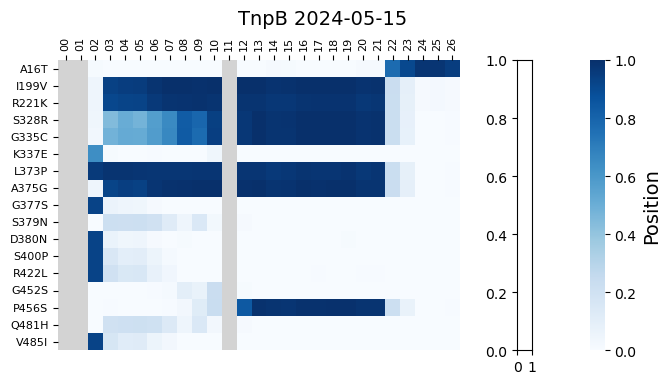

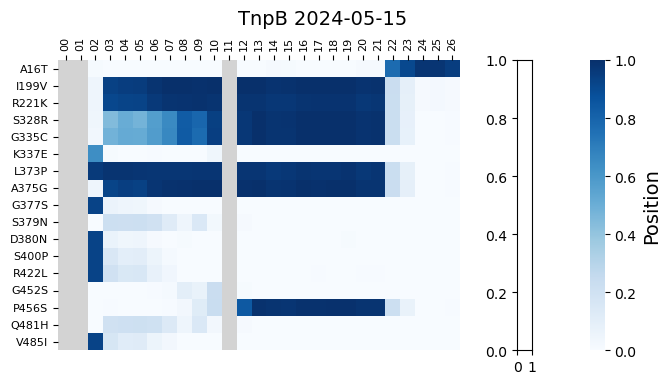

In [6]:
# from genotyping import genotype

samples['aa_dist'] = samples['sample'].map(config.aa_dist_file)
top_muts, muts = find_top_mutations(samples.aa_dist, config.ref_aa_seq) # genotype.find_top_mutations
muts.loc[muts.index, samples.read_counts < config.min_reads_th] = np.nan
muts = muts[sorted(muts.columns)]

# create position labels
top_muts = top_muts.drop(index=[], errors='ignore').sort_index()
top_muts_labelled = top_muts.reset_index()
top_muts_labelled['WT'] = top_muts_labelled.Position.map(lambda pos: config.ref_aa_seq[pos-1])
top_muts_labelled['label'] = top_muts_labelled.WT + top_muts_labelled.Position.astype(str) + top_muts_labelled.TopMutation
top_muts_labelled = top_muts_labelled.set_index('Position')

plot_muts_heatmap(muts, None, None, title=f'TnpB 2024-05-15', pos_labels=top_muts_labelled.label, vlines=[])



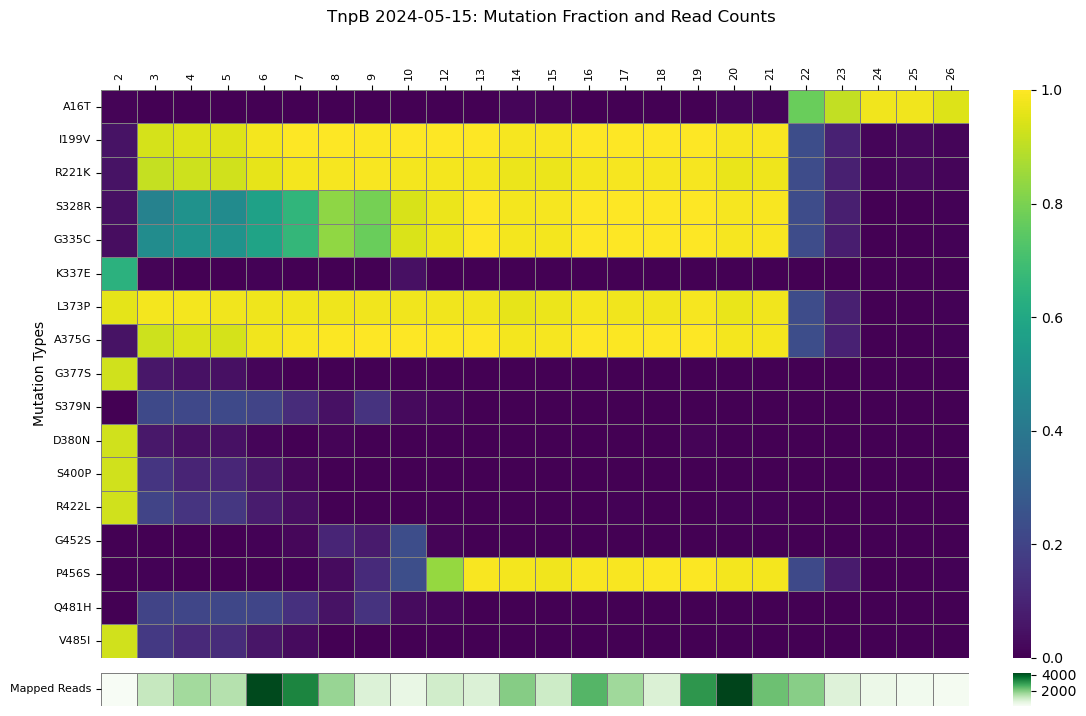

In [7]:
# from genotyping import genotype

samples['aa_dist'] = samples['sample'].map(config.aa_dist_file)
top_muts, muts = find_top_mutations(samples.aa_dist, config.ref_aa_seq)  # genotype.find_top_mutations
muts.loc[muts.index, samples.read_counts < config.min_reads_th] = np.nan
muts = muts[sorted(muts.columns)]

# create position labels
top_muts = top_muts.drop(index=[], errors='ignore').sort_index()
top_muts_labelled = top_muts.reset_index()
top_muts_labelled['WT'] = top_muts_labelled.Position.map(lambda pos: config.ref_aa_seq[pos - 1])
top_muts_labelled['label'] = (
    top_muts_labelled.WT
    + top_muts_labelled.Position.astype(str)
    + top_muts_labelled.TopMutation
)
top_muts_labelled = top_muts_labelled.set_index('Position')

def plot_fraction_ct_lagoon_mapped_heatmap(
    heatmap_data,
    samples,
    time_column='real_time_point_1',
    mapped_reads_column='mapped_reads',
    figsize=(20, 16),
    cmap='viridis',
    title='',
):
    import matplotlib.gridspec as gridspec
    import numpy as np
    import seaborn as sns
    import matplotlib.pyplot as plt

    def extract_time_value(col):
        col_str = str(col)
        if '_L' in col_str:
            return float(col_str.split('_L')[-1])
        return float(col_str)

    # Sort columns by timepoint
    sorted_columns = sorted(heatmap_data.columns, key=extract_time_value)
    hours = [extract_time_value(col) for col in sorted_columns]

    sample_lookup = samples.copy()
    sample_lookup[time_column] = pd.to_numeric(sample_lookup[time_column], errors='coerce')
    sample_lookup = (
        sample_lookup
        .dropna(subset=[time_column])
        .drop_duplicates(subset=[time_column])
        .set_index(time_column)
        .sort_index()
    )

    # Reorder heatmap_data and adjust column labels
    heatmap_data = heatmap_data.reindex(columns=sorted_columns)
    heatmap_data.columns = [f'{extract_time_value(col):g}' for col in sorted_columns]

    mapped_reads = sample_lookup.reindex(hours)[mapped_reads_column].values

    # Set up a gridspec with two rows; the top is larger
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(
        2,
        2,
        width_ratios=[len(heatmap_data.columns), 0.5],
        height_ratios=[len(heatmap_data.index), 1],
        wspace=0.1,
        hspace=0.05,
    )

    # Top: mutation fraction heatmap
    ax0 = plt.subplot(gs[0, 0])
    ax0_cbar = plt.subplot(gs[0, 1])
    sns.heatmap(
        heatmap_data,
        cmap=cmap,
        ax=ax0,
        cbar=True,
        cbar_ax=ax0_cbar,
        xticklabels=heatmap_data.columns,
        yticklabels=heatmap_data.index,
        linewidths=0.5,
        linecolor='gray',
        vmin=0.0,
        vmax=1.0,
    )
    ax0.set_yticklabels(ax0.get_yticklabels(), rotation=0, fontsize=8)
    ax0.set_ylabel('Mutation Types')
    ax0.xaxis.tick_top()

    max_ticks = 100
    n_columns = len(heatmap_data.columns)
    if n_columns > max_ticks:
        tick_indices = np.linspace(0, n_columns - 1, max_ticks, dtype=int)
        ax0.set_xticks(tick_indices)
        ax0.set_xticklabels(
            [heatmap_data.columns[i] for i in tick_indices],
            rotation=90,
            fontsize=8,
        )
    else:
        ax0.set_xticklabels(ax0.get_xticklabels(), rotation=90, fontsize=8)

    # Bottom: mapped reads heatmap
    mapped_array = np.reshape(mapped_reads, (1, -1))
    ax1 = plt.subplot(gs[1, 0])
    ax1_cbar = plt.subplot(gs[1, 1])
    sns.heatmap(
        mapped_array,
        cmap='Greens',
        ax=ax1,
        cbar=True,
        cbar_ax=ax1_cbar,
        xticklabels=False,
        yticklabels=['Mapped Reads'],
        linewidths=0.5,
        linecolor='gray',
    )
    ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0, fontsize=8)

    plt.suptitle(title)
    plt.show()

    return fig

excluded_timepoints = {0, 1, 11}

muts_for_plot = muts.copy()
muts_for_plot.index = top_muts_labelled.loc[muts_for_plot.index, 'label']
muts_for_plot = muts_for_plot.loc[:, pd.to_numeric(muts_for_plot.columns, errors='coerce').isin(excluded_timepoints) == False]

samples_for_plot = samples.reset_index().copy()
samples_for_plot['timepoint_num'] = pd.to_numeric(samples_for_plot['timepoint'], errors='coerce')
samples_for_plot = samples_for_plot.loc[~samples_for_plot['timepoint_num'].isin(excluded_timepoints)].copy()

fig = plot_fraction_ct_lagoon_mapped_heatmap(
    muts_for_plot,
    samples_for_plot,
    time_column='timepoint_num',
    mapped_reads_column='read_counts',
    figsize=(12, 8),
    cmap='viridis',
    title='TnpB 2024-05-15: Mutation Fraction and Read Counts',
)
fig.savefig('results/mutation_fraction_mapped_reads.pdf', bbox_inches='tight',dpi=600)



In [8]:
samples_for_plot

,timepoint,sample,fgcz_fastq,renamed_fastq,read_counts,aa_dist,timepoint_num
1,08,A8-03_TnpB_L8,o35218.bc1005--bc1035.fastq.gz,A8-03_TnpB_L8.fastq.gz,1784,out/aa_dist/A8-03_TnpB_L8.aa_dist.csv,8
2,16,A8-03_TnpB_L16,o35218.bc1005--bc1044.fastq.gz,A8-03_TnpB_L16.fastq.gz,2517,out/aa_dist/A8-03_TnpB_L16.aa_dist.csv,16
3,24,A8-03_TnpB_L24,o35218.bc1005--bc1045.fastq.gz,A8-03_TnpB_L24.fastq.gz,452,out/aa_dist/A8-03_TnpB_L24.aa_dist.csv,24
5,17,A8-03_TnpB_L17,o35218.bc1007--bc1044.fastq.gz,A8-03_TnpB_L17.fastq.gz,1689,out/aa_dist/A8-03_TnpB_L17.aa_dist.csv,17
6,25,A8-03_TnpB_L25,o35218.bc1007--bc1045.fastq.gz,A8-03_TnpB_L25.fastq.gz,310,out/aa_dist/A8-03_TnpB_L25.aa_dist.csv,25
7,02,A8-03_TnpB_L2,o35218.bc1008--bc1033.fastq.gz,A8-03_TnpB_L2.fastq.gz,125,out/aa_dist/A8-03_TnpB_L2.aa_dist.csv,2
8,10,A8-03_TnpB_L10,o35218.bc1008--bc1035.fastq.gz,A8-03_TnpB_L10.fastq.gz,537,out/aa_dist/A8-03_TnpB_L10.aa_dist.csv,10
9,18,A8-03_TnpB_L18,o35218.bc1008--bc1044.fastq.gz,A8-03_TnpB_L18.fastq.gz,828,out/aa_dist/A8-03_TnpB_L18.aa_dist.csv,18
10,03,A8-03_TnpB_L3,o35218.bc1012--bc1033.fastq.gz,A8-03_TnpB_L3.fastq.gz,1186,out/aa_dist/A8-03_TnpB_L3.aa_dist.csv,3
12,19,A8-03_TnpB_L19,o35218.bc1012--bc1044.fastq.gz,A8-03_TnpB_L19.fastq.gz,3059,out/aa_dist/A8-03_TnpB_L19.aa_dist.csv,19


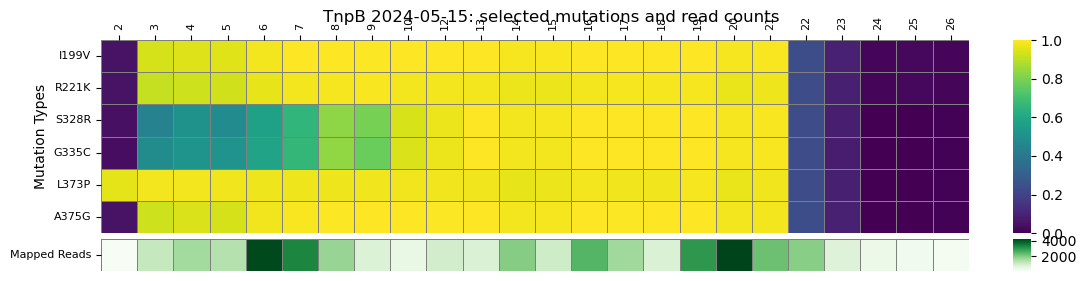

In [9]:
# Same heatmap, restricted to a hand-picked set of mutations
selected_muts = ['I199V', 'R221K', 'S328R', 'G335C', 'L373P', 'A375G']

missing = [m for m in selected_muts if m not in muts_for_plot.index]
if missing:
    print('Not present in the heatmap index (the top mutation at that position differs):', missing)
    print('Available labels at those positions:',
          [lbl for lbl in muts_for_plot.index
           if any(lbl[1:-1] == m[1:-1] for m in missing)])

muts_selected = muts_for_plot.loc[[m for m in selected_muts if m in muts_for_plot.index]]

fig_selected = plot_fraction_ct_lagoon_mapped_heatmap(
    muts_selected,
    samples_for_plot,
    time_column='timepoint_num',
    mapped_reads_column='read_counts',
    figsize=(12, 3),
    cmap='viridis',
    title='TnpB 2024-05-15: selected mutations and read counts',
)
fig_selected.savefig('results/mutation_fraction_selected_muts.pdf', bbox_inches='tight', dpi=600)
